# Daily PACE L2 Chl → NSIDC North Polar Stereographic + Flag Analysis

Parallel to the L3M pipeline (`figS10_S11_clouds-and-valid-days.ipynb`), but using **PACE OCI L2 BGC** swath data instead of L3-mapped. The point: at L2 every pixel carries its `l2_flags` bitmask, so we can attribute missing-pixel causes (cloud-ice, atmcorr fail, high SZA, glint, ...) instead of getting an opaque NaN.

**Differences from L3M:**
- Source data is irregular swaths (per-pixel `latitude` / `longitude` arrays) instead of a regular global grid.
- Multiple swaths per day (~6–10 PACE overpasses cover the Arctic each day); we aggregate sum + count across all of them into the polar grid.
- Significantly more data: each L2 file is ~100–200 MB vs. ~15 MB for L3M; ~2 GB/day streamed instead of ~100 MB.
- Adds a **flag analysis** section that bins per-flag pixel counts onto the polar grid alongside the chl mean.

Starting with **2024-05-01 only** to validate the pipeline before scaling up.

## Dependencies

All already installed in `pace_chl_v2`. Run cells in the same kernel.

In [1]:
import gzip
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import xarray as xr
import dask.array as da
import earthaccess
import h5netcdf
from pyresample import AreaDefinition
from pyresample.bucket import BucketResampler
from matplotlib.path import Path as MplPath
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy import stats

## Configuration

In [2]:
START_DATE = date(2024, 3, 1)        # PACE first ocean-color data
END_DATE   = date.today()            # through today
LAT_MIN    = 30
ARCTIC_BBOX = (-180.0, float(LAT_MIN), 180.0, 90.0)   # earthaccess bounding_box filter

OUT_DIR = Path.home() / "ADD_YOUR_PATH" / "pace" / "outputs_L2"  # add your path
OUT_DIR.mkdir(parents=True, exist_ok=True)

PACE_SHORT_NAME = "PACE_OCI_L2_BGC"

## EarthData authentication

In [ ]:
auth = earthaccess.login(persist=True)

## Define the destination grid — NSIDC North Polar Stereographic, 12.5 km

Same as the L3M notebook: Larry's grid doubled to 12.5 km, EPSG:3411 (Hughes 1980 ellipsoid).

In [6]:
target_area = AreaDefinition(
    area_id="nsidc_north_polar_stereo_12_5km",
    description="NSIDC North Polar Stereographic, 12.5 km (Larry's doubled grid)",
    proj_id="EPSG:3411",
    projection={
        "proj":   "stere",
        "lat_0":  90,
        "lat_ts": 70,
        "lon_0": -45,
        "x_0":    0,
        "y_0":    0,
        "a":      6378273,
        "b":      6356889.449,
        "units":  "m",
    },
    width=608,
    height=896,
    area_extent=(-3_850_000, -5_350_000, 3_750_000, 5_850_000),
)
print(target_area)

Area ID: nsidc_north_polar_stereo_12_5km
Description: NSIDC North Polar Stereographic, 12.5 km (Larry's doubled grid)
Projection ID: EPSG:3411
Projection: {'a': '6378273', 'lat_0': '90', 'lat_ts': '70', 'lon_0': '-45', 'no_defs': 'None', 'proj': 'stere', 'rf': '298.279411123064', 'type': 'crs', 'units': 'm', 'x_0': '0', 'y_0': '0'}
Number of columns: 608
Number of rows: 896
Area extent: (-3850000, -5350000, 3750000, 5850000)


## Helpers — same `.dbl.gz` and Zarr writers as the L3M notebook

In [7]:
def write_dbl_gz(arr_2d, out_path):
    """IDL-compatible gzipped column-major float64 bytes."""
    arr = arr_2d.astype(np.float64)
    arr = np.where(np.isnan(arr), -1.0, arr)
    with gzip.open(out_path, "wb") as f:
        f.write(arr.tobytes())   # default C-order = IDL DBLARR(width, height) byte order

def write_zarr(arr_2d, out_path, target_area, source_granule_id, t):
    x_coords, y_coords = target_area.get_proj_vectors()
    ds = xr.Dataset(
        {"chlor_a": (("y", "x"), arr_2d.astype(np.float32))},
        coords={"x": ("x", x_coords), "y": ("y", y_coords), "time": t},
        attrs={
            "source_granule":  source_granule_id,
            "source_product":  PACE_SHORT_NAME,
            "target_grid":     target_area.area_id,
            "projection":      target_area.proj_str,
            "lat_min_subset":  LAT_MIN,
            "created_by":      "figS10_S11_clouds-and-valid-days.ipynb",
        },
    )
    ds["chlor_a"].attrs.update({"units": "mg m-3", "long_name": "Chlorophyll-a concentration"})
    ds["x"].attrs.update({"units": "m", "standard_name": "projection_x_coordinate"})
    ds["y"].attrs.update({"units": "m", "standard_name": "projection_y_coordinate"})
    ds.to_zarr(out_path, mode="w")

## DBO box masks on the destination grid

In [ ]:
# DBO box polygons come from the spreadsheet shipped at the root of this repository.
_XLSX_NAME = "DBO1_8_StationAndBoxCoordinates_DBO4nOnly_072522.xlsx"
DBO_XLSX = next((p / _XLSX_NAME for p in (Path.cwd(), Path.cwd().parent, Path.home()) if (p / _XLSX_NAME).exists()), None)
if DBO_XLSX is None:
    raise FileNotFoundError(f"{_XLSX_NAME} not found next to this notebook, in the repository root, or in $HOME")  # add your path
boxes_df = pd.read_excel(DBO_XLSX, sheet_name="DBOboxes1_8_050522")
boxes = {}
for region, grp in boxes_df.groupby("DBO Region", sort=False):
    boxes[region] = list(zip(grp["Longitude"].values, grp["Latitude"].values))

lons2d, lats2d = target_area.get_lonlats()
grid_points = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {
    name: MplPath(corners).contains_points(grid_points).reshape(lons2d.shape)
    for name, corners in boxes.items()
}
for name, m in box_masks.items():
    print(f"  {name}: {m.sum():>6,} grid cells inside box")


  DBO1:    258 grid cells inside box
  DBO2:     63 grid cells inside box
  DBO3:    267 grid cells inside box
  DBO4:    132 grid cells inside box
  DBO5:     37 grid cells inside box
  DBO6:     75 grid cells inside box
  DBO7:     79 grid cells inside box
  DBO8:     78 grid cells inside box

Time series spans 7 day(s)


## L3M long-form time series — May 1 → October 1, 2024

Switching back to L3M for the longer time series:

- **~10 MB/day** vs. ~2 GB/day for L2 — five months of L3M streams in ~15 min instead of ~10 hours.
- **~154 daily points** per DBO box is enough to see the seasonal cycle (spring greenup → summer decline).
- Outputs go to the **same `~/ADD_YOUR_PATH/outputs/`** directory the L3M notebook uses, so the May 1–7 daily Zarrs already on disk get skipped — only May 8 → Oct 1 stream fresh.

The DBO time-series plot below uses a **log y-axis** since chl spans orders of magnitude across the season.

In [52]:
L3_START_DATE = date(2024, 5, 1)
L3_END_DATE   = date(2026, 6, 1)
L3_SHORT_NAME = "PACE_OCI_L3M_CHL"
L3_OUT_DIR    = Path.home() / "ADD_YOUR_PATH" / "outputs"  # add your path
L3_OUT_DIR.mkdir(parents=True, exist_ok=True)

# Search and filter to daily (DAY) cadence
_all_l3 = earthaccess.search_data(
    short_name=L3_SHORT_NAME,
    temporal=(L3_START_DATE.isoformat(), L3_END_DATE.isoformat()),
)
l3_daily = [g for g in _all_l3 if ".L3m.DAY." in g["umm"]["GranuleUR"]]
print(f"{len(_all_l3)} L3M granules → {len(l3_daily)} after DAY-only filter")

def _granule_date(g):
    t = g["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]
    return date.fromisoformat(t[:10])

l3_by_day = {}
for g in l3_daily:
    l3_by_day.setdefault(_granule_date(g), g)
print(f"Unique days: {len(l3_by_day)}  ({min(l3_by_day)} → {max(l3_by_day)})")

1664 L3M granules → 1314 after DAY-only filter
Unique days: 657  (2024-05-01 → 2026-02-28)


In [53]:
def write_zarr_l3(arr_2d, out_path, target_area, source_granule_id, t):
    """Like write_zarr but stamps source_product as the L3M short name."""
    x_coords, y_coords = target_area.get_proj_vectors()
    ds = xr.Dataset(
        {"chlor_a": (("y", "x"), arr_2d.astype(np.float32))},
        coords={"x": ("x", x_coords), "y": ("y", y_coords), "time": t},
        attrs={
            "source_granule":  source_granule_id,
            "source_product":  L3_SHORT_NAME,
            "target_grid":     target_area.area_id,
            "projection":      target_area.proj_str,
            "lat_min_subset":  LAT_MIN,
            "created_by":      "figS10_S11_clouds-and-valid-days.ipynb (L3M section)",
        },
    )
    ds["chlor_a"].attrs.update({"units": "mg m-3", "long_name": "Chlorophyll-a concentration"})
    ds["x"].attrs.update({"units": "m", "standard_name": "projection_x_coordinate"})
    ds["y"].attrs.update({"units": "m", "standard_name": "projection_y_coordinate"})
    ds.to_zarr(out_path, mode="w")

def process_one_day_l3(granule, target_area, out_dir):
    d = _granule_date(granule)
    yyyy, doy = d.year, d.timetuple().tm_yday
    dbl_path  = out_dir / f"n{yyyy}{doy:03d}_chlor_PACE.dbl.gz"
    zarr_path = out_dir / f"n{yyyy}{doy:03d}_chlor_PACE.zarr"

    if dbl_path.exists() and zarr_path.exists():
        return "skip"

    files = earthaccess.open([granule])
    with xr.open_dataset(files[0], engine="h5netcdf", chunks={}) as ds:
        chl_var = "chlor_a" if "chlor_a" in ds.variables else list(ds.data_vars)[0]
        arctic  = ds[chl_var].sel(lat=slice(90, LAT_MIN))
        lon_1d  = arctic["lon"].values
        lat_1d  = arctic["lat"].values
        chl_2d  = arctic.values

    chl_2d = np.where((chl_2d > 0) & np.isfinite(chl_2d), chl_2d, np.nan)
    src_lon_np, src_lat_np = np.meshgrid(lon_1d, lat_1d)
    src_lon = da.from_array(src_lon_np, chunks="auto")
    src_lat = da.from_array(src_lat_np, chunks="auto")
    src_chl = da.from_array(chl_2d,     chunks="auto")

    resampler = BucketResampler(target_area, src_lon, src_lat)
    polar_chl = resampler.get_average(src_chl)
    if hasattr(polar_chl, "compute"):
        polar_chl = polar_chl.compute()

    write_dbl_gz(polar_chl, dbl_path)
    write_zarr_l3(polar_chl, zarr_path, target_area,
                  granule["umm"]["GranuleUR"], np.datetime64(d.isoformat()))
    return "wrote"

In [54]:
n_wrote, n_skip = 0, 0
for i, (d, g) in enumerate(sorted(l3_by_day.items()), 1):
    status = process_one_day_l3(g, target_area, L3_OUT_DIR)
    if status == "wrote":
        n_wrote += 1
        print(f"[{i:3d}/{len(l3_by_day)}] {d}  ✓")
    else:
        n_skip += 1
        if i % 10 == 0 or i == len(l3_by_day):
            print(f"[{i:3d}/{len(l3_by_day)}] {d}  (skipped, already on disk)")

print(f"\nDone: {n_wrote} new days written, {n_skip} skipped.")
print(f"Total daily Zarrs in {L3_OUT_DIR}: {len(sorted(L3_OUT_DIR.glob('n2024*_chlor_PACE.zarr')))}")

[ 10/657] 2024-05-10  (skipped, already on disk)
[ 20/657] 2024-05-20  (skipped, already on disk)
[ 30/657] 2024-06-04  (skipped, already on disk)
[ 40/657] 2024-06-14  (skipped, already on disk)
[ 50/657] 2024-06-24  (skipped, already on disk)
[ 60/657] 2024-07-04  (skipped, already on disk)
[ 70/657] 2024-07-14  (skipped, already on disk)
[ 80/657] 2024-07-24  (skipped, already on disk)
[ 90/657] 2024-08-03  (skipped, already on disk)
[100/657] 2024-08-13  (skipped, already on disk)
[110/657] 2024-08-23  (skipped, already on disk)
[120/657] 2024-09-02  (skipped, already on disk)
[130/657] 2024-09-14  (skipped, already on disk)
[140/657] 2024-09-24  (skipped, already on disk)


[148/657] 2024-10-02  ✓


[149/657] 2024-10-03  ✓


[150/657] 2024-10-04  ✓


[151/657] 2024-10-05  ✓


[152/657] 2024-10-06  ✓


... (502 outputs left out)

[655/657] 2026-02-26  ✓


[656/657] 2026-02-27  ✓


QUEUEING TASKS | : 100%|██████████| 1/1 [00:00<00:00, 7294.44it/s]
PROCESSING TASKS | : 100%|██████████| 1/1 [00:02<00:00,  2.25s/it]
COLLECTING RESULTS | : 100%|██████████| 1/1 [00:00<00:00, 5777.28it/s]


[657/657] 2026-02-28  ✓

Done: 510 new days written, 147 skipped.
Total daily Zarrs in ~/ADD_YOUR_PATH/outputs: 236


## Per-DBO-box coverage — valid PACE days per box (Fig. S10, PACE panel + table)

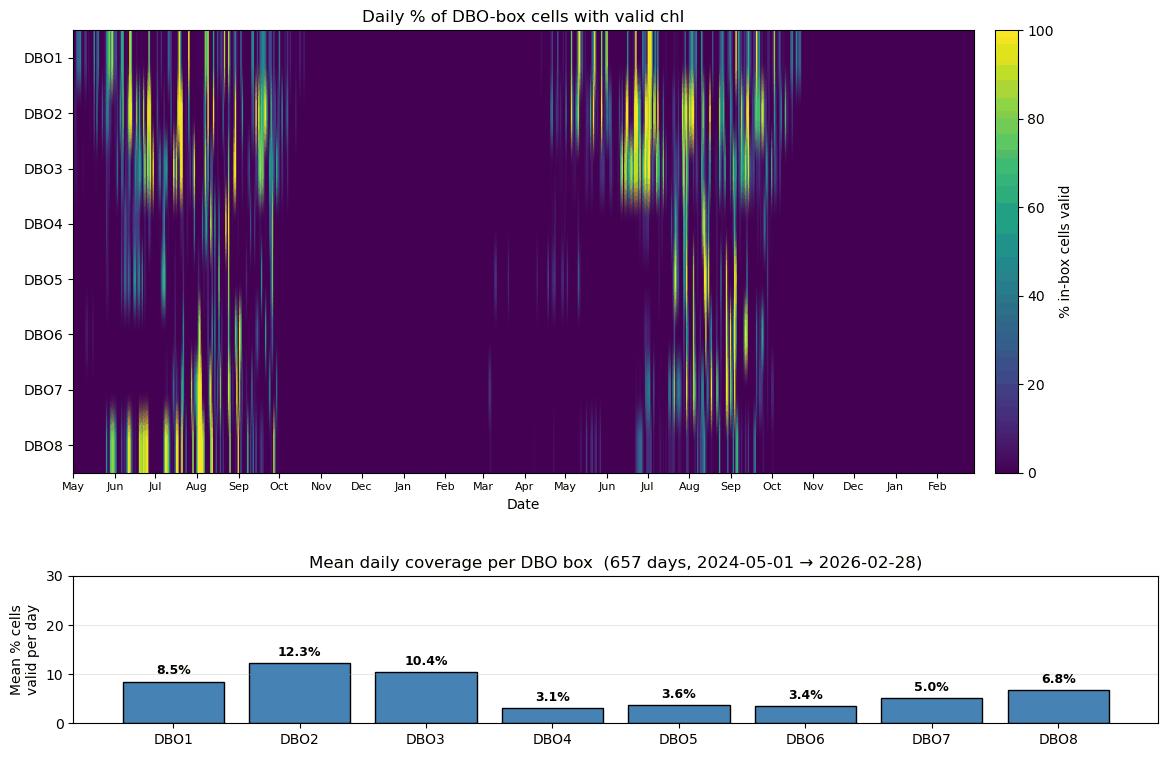


Box     n_cells    mean%   median%    max%   days≥10%   days≥50%
DBO1        258      8.5       0.0   100.0        123         41
DBO2         63     12.3       0.0   100.0        145         73
DBO3        267     10.4       0.0   100.0        135         60
DBO4        132      3.1       0.0    98.5         46         11
DBO5         37      3.6       0.0    97.3         55         18
DBO6         75      3.4       0.0   100.0         44         20
DBO7         79      5.0       0.0   100.0         65         25
DBO8         78      6.8       0.0    98.7         88         39


In [61]:
# Reload ds_l3 / box_masks if not already in scope
import matplotlib.dates as mdates
if "ds_l3" not in dir() or "chlor_a" not in ds_l3.data_vars:
    l3_zarr_paths = sorted(L3_OUT_DIR.glob("n20*_chlor_PACE.zarr"))
    ds_l3 = xr.concat([xr.open_zarr(p) for p in l3_zarr_paths], dim="time").sortby("time")
    ds_l3 = ds_l3.sel(time=slice(np.datetime64(L3_START_DATE.isoformat()),
                                  np.datetime64(L3_END_DATE.isoformat())))
if "box_masks" not in dir():
    raise RuntimeError("box_masks not in scope — run the DBO box-loading cell first.")

box_names = list(box_masks.keys())
n_boxes   = len(box_names)
times     = ds_l3.time.values
n_days    = ds_l3.sizes["time"]

# coverage[i, t] = fraction of in-box cells with valid chl on day t
coverage = np.zeros((n_boxes, n_days), dtype=np.float32)
for i, (name, mask) in enumerate(box_masks.items()):
    n_in_box = int(mask.sum())
    if n_in_box == 0:
        continue
    mask_da       = xr.DataArray(mask, dims=("y", "x"))
    in_box        = ds_l3["chlor_a"].where(mask_da)
    valid_per_day = (in_box > 0).sum(dim=("y", "x")).values
    coverage[i]   = valid_per_day / n_in_box

# --- Plot: heatmap (top) + bar chart (bottom) ---
fig = plt.figure(figsize=(14, 9))
gs  = fig.add_gridspec(2, 1, height_ratios=[3, 1], hspace=0.35)

# Heatmap
ax_heat = fig.add_subplot(gs[0])
im = ax_heat.imshow(
    coverage * 100, aspect="auto", cmap="viridis", vmin=0, vmax=100,
    extent=[mdates.date2num(times[0]), mdates.date2num(times[-1]),
            n_boxes - 0.5, -0.5],
)
ax_heat.set_yticks(range(n_boxes))
ax_heat.set_yticklabels(box_names)
ax_heat.xaxis_date()
ax_heat.xaxis.set_major_locator(mdates.MonthLocator())
ax_heat.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_heat.xaxis.set_minor_locator(mdates.YearLocator())
ax_heat.xaxis.set_minor_formatter(mdates.DateFormatter("\n\n%Y"))
ax_heat.tick_params(axis="x", which="major", labelsize=8)
ax_heat.tick_params(axis="x", which="minor", labelsize=10, length=0)
ax_heat.set_xlabel("Date")
ax_heat.set_title("Daily % of DBO-box cells with valid chl")
fig.colorbar(im, ax=ax_heat, orientation="vertical", pad=0.02,
             label="% in-box cells valid")

# Bar chart — mean daily coverage per box, with exact value labels
ax_bar = fig.add_subplot(gs[1])
mean_cov = coverage.mean(axis=1) * 100
bars = ax_bar.bar(box_names, mean_cov, color="steelblue", edgecolor="black")
for x, y in zip(box_names, mean_cov):
    ax_bar.text(x, y + 1.5, f"{y:.1f}%", ha="center", fontsize=9, fontweight="bold")
ax_bar.set_ylabel("Mean % cells\nvalid per day")
ax_bar.set_ylim(0, max(mean_cov.max() + 8, 30))
ax_bar.grid(alpha=0.3, axis="y")
ax_bar.set_title(f"Mean daily coverage per DBO box  ({n_days} days, "
                 f"{str(times[0])[:10]} → {str(times[-1])[:10]})")

plt.show()

# --- Numeric summary table ---
print(f"\n{'Box':<6} {'n_cells':>8} {'mean%':>8} {'median%':>9} {'max%':>7} "
      f"{'days≥10%':>10} {'days≥50%':>10}")
for i, name in enumerate(box_names):
    c = coverage[i] * 100
    print(f"{name:<6} {int(box_masks[name].sum()):>8,} "
          f"{c.mean():>8.1f} {np.median(c):>9.1f} {c.max():>7.1f} "
          f"{int((c >= 10).sum()):>10} {int((c >= 50).sum()):>10}")

---

# Part B — MODIS cloud fraction: Fig. S11 trends and the Fig. S10 clear-sky-days panel

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# MODIS Aqua **cloud fraction** → DBO + Aleutians, EASE-Grid 2.0 North (streaming, no storage)

Cloud-fraction companion to the SST/chl notebooks. **Streams** the MODIS-COSP daily L3 cloud product,
grids each day onto the **same EASE-2 4 km DBO grid**, and folds it into **in-memory accumulators** —
**nothing is written to disk**. One streaming pass builds everything: per-box time series, the
record-mean map, and the per-year May–Sep frames for the trend map / GIF.

### Product
- **`MCD06COSP_D3_MODIS` v6.2** (`concept_id C2263893831-LAADS`) — netCDF4, streamable. Cloud fraction
  = `Cloud_Mask_Fraction/Mean` (0–1). This is the **L3 daily gridding of the MYD35 cloud mask** — the
  same cloud-mask quantity the DBO website reports as "7-day average cloud fraction (%) from MYD35".
- **Native 1°**, nearest-neighboured onto 4 km (blocky maps; read as a regional/seasonal metric).
- Verify the variable path with §3b before the full run.

## 1. Imports

In [3]:
import time as _time, warnings, gc
from pathlib import Path
from datetime import date, timedelta
from concurrent.futures import ThreadPoolExecutor, wait, FIRST_COMPLETED

import numpy as np, pandas as pd, xarray as xr
import earthaccess
from pyresample import AreaDefinition, geometry
from pyresample.kd_tree import resample_nearest
from matplotlib.path import Path as MplPath
import matplotlib.pyplot as plt, matplotlib.dates as mdates
import matplotlib.colors as mcolors
import cartopy.crs as ccrs, cartopy.feature as cfeature
from scipy import stats
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore")
print("imports OK")

imports OK


## 2. Configuration — product, domain, EASE-2 grid, DBO boxes

In [4]:
CLOUD_SHORT   = "MCD06COSP_D3_MODIS"
CLOUD_VERSION = "6.2"
CLOUD_CONCEPT = "C2263893831-LAADS"     # exact collection id (most reliable; monthly M3 = C2263894888-LAADS)
CF_GROUP      = "Cloud_Mask_Fraction"   # netCDF group; cloud fraction at <group>/<subvar>
CF_SUBVAR     = "Mean"                  # 0..1
LATN, LONN    = "latitude", "longitude"

START_DATE = date(2002, 7, 4)
END_DATE   = date.today()
LAT_MIN, LAT_MAX = 45, 84
LON_MIN, LON_MAX = -180, -100
ROI = 80_000                            # nearest-neighbour radius (m)
N_WORKERS = 8
GROW = [5, 6, 7, 8, 9]                  # May–Sep season for the annual frames

dbo_area = AreaDefinition(
    area_id="ease2_north_dbo_4km",
    description="EASE-Grid 2.0 North subset: Aleutians -> Beaufort (DBO1-8), 4 km",
    proj_id="EPSG:6931",
    projection={"proj":"laea","lat_0":90,"lon_0":0,"x_0":0,"y_0":0,"datum":"WGS84","units":"m"},
    width=906, height=845, area_extent=(-3_624_000, 992_000, 0, 4_372_000))

# OPTIONAL tiny cache of derived products only (box_ts + mean_map + annual_cf, ~80 MB) — NOT per-day
# data. Off by default = pure streaming, zero storage. Flip True to skip re-streaming on restart.
# Checkpointing: pickle the accumulators every CKPT_EVERY days so a kernel/server crash RESUMES
# instead of restarting from day 0 (~160 MB; rm the file to force a clean restart).
CHECKPOINT = True
CKPT_PATH  = Path.home() / "modis_cloudfraction_ckpt.pkl"  # add your path
CKPT_EVERY = 500

# OPTIONAL tiny cache of FINISHED derived products (box_ts + mean_map + annual_cf) for instant reload.
CACHE_DERIVED = False
CACHE_PATH    = Path.home() / "modis_cloudfraction_products.pkl"  # add your path

DBO_BOXES = {
    "DBO1": [(63.769462,-172.312422),(61.945988,-172.186927),(61.846516,-175.790978),(63.662718,-176.147111)],
    "DBO2": [(65.107747,-170.865176),(65.097001,-167.859549),(64.481828,-167.907758),(64.493658,-170.840669)],
    "DBO3": [(66.785880,-171.330008),(68.608869,-171.419334),(68.572412,-166.481029),(66.752281,-166.755808)],
    "DBO4": [(71.994000,-164.226000),(71.801000,-159.729000),(70.641000,-160.305000),(70.821000,-164.556000)],
    "DBO5": [(71.807730,-158.537691),(71.635583,-155.931220),(71.110941,-156.307277),(71.278277,-158.847920)],
    "DBO6": [(71.850000,-150.108000),(70.890000,-150.976000),(71.159000,-153.865000),(72.119000,-152.980000)],
    "DBO7": [(70.868000,-141.528000),(69.946000,-142.679000),(70.333000,-145.439000),(71.253000,-144.256000)],
    "DBO8": [(70.834000,-125.155000),(70.049000,-126.997000),(70.664000,-129.354000),(71.442000,-127.431000)],
}
data_crs = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-152)
x0, y0, x1, y1 = dbo_area.area_extent
print(f"{CLOUD_SHORT} v{CLOUD_VERSION} | {START_DATE} -> {END_DATE} | grid {dbo_area.shape} | streaming (no disk)")

MCD06COSP_D3_MODIS v6.2 | 2002-07-04 -> 2026-08-18 | grid (845, 906) | streaming (no disk)


## 3. EarthData auth + search the daily granules

In [5]:
auth = earthaccess.login(persist=True)

def _search(s, e, limit=30000):
    # count= -> earthaccess paginates via query.get() instead of get_all()->hits(); avoids the
    # page_size=0 count query that returns CMR 500 for this LAADS collection.
    kw = {"concept_id": CLOUD_CONCEPT} if CLOUD_CONCEPT else {"short_name": CLOUD_SHORT, "version": CLOUD_VERSION}
    for k in range(5):
        try: return earthaccess.search_data(temporal=(s, e), count=limit, **kw)
        except Exception: _time.sleep(2*(k+1))
    raise RuntimeError("CMR search failed")

def granule_date(g):
    return date.fromisoformat(g["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"][:10])

all_granules = _search(START_DATE.isoformat(), END_DATE.isoformat())
granules_by_day = {}
for g in all_granules:
    granules_by_day.setdefault(granule_date(g), g)
print(f"{len(all_granules)} granules | {len(granules_by_day)} unique days "
      f"({min(granules_by_day)} -> {max(granules_by_day)})" if granules_by_day else "no granules found")

8772 granules | 8772 unique days (2002-07-04 -> 2026-08-10)


## 4. Single-day reader + gridder (stream → EASE-2, in memory, no write)

In [7]:
def _read_cf(f):
    with xr.open_dataset(f, engine="h5netcdf") as root:
        lat = np.asarray(root[LATN].values, float); lon = np.asarray(root[LONN].values, float)
    with xr.open_dataset(f, engine="h5netcdf", group=CF_GROUP) as g:
        cf = np.asarray(g[CF_SUBVAR].values, float)
    if cf.shape != (lat.size, lon.size) and cf.T.shape == (lat.size, lon.size):
        cf = cf.T
    return lat, lon, cf

def cf_to_grid(lat, lon, cf, area):
    yi = (lat >= LAT_MIN) & (lat <= LAT_MAX); xi = (lon >= LON_MIN) & (lon <= LON_MAX)
    lon2d, lat2d = np.meshgrid(lon[xi], lat[yi])
    swath = geometry.SwathDefinition(lons=lon2d, lats=lat2d)
    grid = resample_nearest(swath, cf[np.ix_(yi, xi)], area, radius_of_influence=ROI,
                            fill_value=np.nan, reduce_data=False)
    return grid.astype(np.float32)

def project_day(granule, area):
    """Stream one granule -> 2-D EASE-2 cloud-fraction array. Closes the remote file (no leak)."""
    f = earthaccess.open([granule], show_progress=False)[0]
    try:
        lat, lon, cf = _read_cf(f)
    finally:
        try: f.close()
        except Exception: pass
    return cf_to_grid(lat, lon, cf, area)

## 5. DBO box masks on the EASE-2 grid

In [8]:
lons2d, lats2d = dbo_area.get_lonlats()
grid_pts = np.column_stack([lons2d.ravel(), lats2d.ravel()])
box_masks = {name: MplPath([(lo,la) for la,lo in corners] + [(corners[0][1], corners[0][0])])
                       .contains_points(grid_pts).reshape(lons2d.shape)
             for name, corners in DBO_BOXES.items()}
for name, m in box_masks.items():
    print(f"  {name}: {int(m.sum()):>6,} grid cells inside box")

  DBO1:  2,412 grid cells inside box
  DBO2:    605 grid cells inside box
  DBO3:  2,561 grid cells inside box
  DBO4:  1,293 grid cells inside box
  DBO5:    351 grid cells inside box
  DBO6:    739 grid cells inside box
  DBO7:    773 grid cells inside box
  DBO8:    760 grid cells inside box


## 6. Streaming pass (parallel, memory-bounded) — build everything, write nothing

Threads stream + grid days; the main thread folds each ~3 MB array into accumulators and drops it
(flat memory, no disk). Builds `box_ts`, `mean_map`, and `annual_cf` (per-year May–Sep). Slow cell on
a cold kernel; re-running is a no-op if the products are already in memory.

In [9]:
import pickle
def _have_products():
    return all(k in globals() and globals()[k] is not None for k in ("box_ts","mean_map","annual_cf"))

ny, nx = dbo_area.shape

# restore order: finished products cache > checkpoint > fresh
if CACHE_DERIVED and CACHE_PATH.exists() and not _have_products():
    _d = pickle.load(open(CACHE_PATH, "rb"))
    box_ts, mean_map, annual_cf = _d["box_ts"], _d["mean_map"], _d["annual_cf"]
    print(f"loaded finished products from {CACHE_PATH} — no streaming.")

if _have_products():
    print("products already in memory — skipping the stream.")
else:
    if CHECKPOINT and CKPT_PATH.exists():
        _ck = pickle.load(open(CKPT_PATH, "rb"))
        mean_sum, mean_cnt = _ck["mean_sum"], _ck["mean_cnt"]
        marsep,   box_rows = _ck["marsep"],   _ck["box_rows"]
        print(f"resumed from checkpoint: {len(box_rows)} days already folded.")
    else:
        mean_sum = np.zeros((ny, nx), np.float32); mean_cnt = np.zeros((ny, nx), np.float32)
        marsep = {}; box_rows = {}

    def _stream_one(item):
        d, g = item
        try: return d, project_day(g, dbo_area), None
        except Exception as e: return d, None, f"{type(e).__name__}: {str(e)[:70]}"

    def _fold(d, arr):
        m = np.isfinite(arr)
        mean_sum[m] += arr[m]; mean_cnt[m] += 1
        if d.month in GROW:
            s = marsep.setdefault(d.year, [np.zeros((ny, nx), np.float32), np.zeros((ny, nx), np.float32)])
            s[0][m] += arr[m]; s[1][m] += 1
        bm, bmed = {}, {}
        for n, mask in box_masks.items():
            v = arr[mask & m]
            bm[n]   = float(np.mean(v))   if v.size else np.nan
            bmed[n] = float(np.median(v)) if v.size else np.nan
        box_rows[d] = (bm, bmed)

    def _save_ckpt():
        if not CHECKPOINT: return
        CKPT_PATH.parent.mkdir(parents=True, exist_ok=True)
        tmp = CKPT_PATH.with_suffix(".tmp")
        pickle.dump({"mean_sum": mean_sum, "mean_cnt": mean_cnt,
                     "marsep": marsep, "box_rows": box_rows}, open(tmp, "wb"))
        tmp.replace(CKPT_PATH)                      # atomic-ish: never leaves a half-written file

    remaining = [(d, g) for d, g in sorted(granules_by_day.items()) if d not in box_rows]  # resume
    src = iter(remaining); MAXQ = max(2, N_WORKERS*2)
    t0 = _time.time(); n_ok = n_fail = since = 0
    print(f"{len(box_rows)} done | streaming {len(remaining)} more with {N_WORKERS} workers...")
    with ThreadPoolExecutor(max_workers=N_WORKERS) as ex:
        inflight = set()
        for _ in range(MAXQ):
            try: inflight.add(ex.submit(_stream_one, next(src)))
            except StopIteration: break
        while inflight:
            done, inflight = wait(inflight, return_when=FIRST_COMPLETED)
            for fut in done:
                d, arr, err = fut.result()
                if arr is None:
                    n_fail += 1
                    if n_fail <= 10: print(f"  {d}  X {err}")
                else:
                    _fold(d, arr); n_ok += 1; since += 1
                    if n_ok % 250 == 0: print(f"  {n_ok} ok / {n_fail} failed  ({(_time.time()-t0)/60:.1f} min)")
                    if since >= CKPT_EVERY: _save_ckpt(); gc.collect(); since = 0
                try: inflight.add(ex.submit(_stream_one, next(src)))
                except StopIteration: pass
            del done
    _save_ckpt()

    dates = sorted(box_rows); tcoord = np.array([np.datetime64(d.isoformat()) for d in dates])
    box_ts = {n: {"daily_mean":   xr.DataArray(np.array([box_rows[d][0][n] for d in dates]), dims="time", coords={"time": tcoord}),
                  "daily_median": xr.DataArray(np.array([box_rows[d][1][n] for d in dates]), dims="time", coords={"time": tcoord})}
              for n in box_masks}
    mean_map = np.where(mean_cnt > 0, mean_sum / mean_cnt, np.nan)
    _years = sorted(marsep)
    annual_cf = xr.DataArray(
        np.stack([np.where(marsep[y][1] > 0, marsep[y][0]/marsep[y][1], np.nan) for y in _years]),
        dims=("year","y","x"), coords={"year": _years})
    gc.collect()
    print(f"\nstreamed {n_ok} new days ({n_fail} failed); {len(box_rows)} total -> "
          f"box_ts, mean_map, {len(_years)} annual (May-Sep) frames.")

if CACHE_DERIVED and not CACHE_PATH.exists():
    pickle.dump({"box_ts": box_ts, "mean_map": mean_map, "annual_cf": annual_cf}, open(CACHE_PATH, "wb"))
    print(f"saved finished products ({CACHE_PATH.stat().st_size/1e6:.0f} MB) -> {CACHE_PATH}")

resumed from checkpoint: 8718 days already folded.
8718 done | streaming 54 more with 8 workers...

streamed 54 new days (0 failed); 8772 total -> box_ts, mean_map, 25 annual (May-Sep) frames.


In [10]:
import pickle
pickle.dump({"box_ts": box_ts, "mean_map": mean_map, "annual_cf": annual_cf},
            open(Path.home() / "modis_cloudfraction_products.pkl", "wb"))  # add your path
print("saved")


saved


## 9. Trend helpers (Theil–Sen + Mann–Kendall, naive & AR(1))

In [12]:
def _lag1(x):
    x = np.asarray(x, float); a, b = x[1:], x[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0
def _stars(p):
    return ("***" if p<0.001 else "**" if p<0.01 else "*" if p<0.05 else "ns") if np.isfinite(p) else "n/a"
print("helpers ready")

helpers ready


## 18. Reload the per-box cloud fraction and fit the per-box trend (Fig. S11)

The loader is self-contained: it reads `modis_cloudfraction_products.pkl` (or rebuilds the box means from the streaming checkpoint) so this section runs on a fresh kernel without re-streaming.

In [2]:
# ============================================================================
# LOADER (self-contained) — daily per-box cloud fraction from the streaming cache,
# so this section runs on a fresh kernel without re-streaming. Uses the
# finished-products pkl if present, else rebuilds box means from the checkpoint.
# ============================================================================
import pickle, numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import theilslopes, kendalltau, norm

HOME     = Path.home()  # add your path
PRODUCTS = HOME / "modis_cloudfraction_products.pkl"     # {"box_ts","mean_map","annual_cf"} (from §6 cell)
CKPT     = HOME / "modis_cloudfraction_ckpt.pkl"         # streaming checkpoint (has box_rows)

if PRODUCTS.exists():
    box_ts = pickle.load(open(PRODUCTS, "rb"))["box_ts"]
    cf_box = {n: box_ts[n]["daily_mean"] * 100.0 for n in box_ts}          # fraction -> percent
    print(f"loaded finished products: {PRODUCTS.name}")
elif CKPT.exists():
    box_rows = pickle.load(open(CKPT, "rb"))["box_rows"]                    # {date: (mean_dict, median_dict)}
    dates = sorted(box_rows); tcoord = np.array([np.datetime64(d.isoformat()) for d in dates])
    names = list(box_rows[dates[0]][0])
    cf_box = {n: xr.DataArray(np.array([box_rows[d][0][n] for d in dates]) * 100.0,
                              dims="time", coords={"time": tcoord}) for n in names}
    print(f"rebuilt box means from checkpoint: {CKPT.name} ({len(dates)} days)")
else:
    raise FileNotFoundError(f"Neither {PRODUCTS.name} nor {CKPT.name} in {HOME} — run the §6 streaming pass first.")

_t = pd.to_datetime(next(iter(cf_box.values()))["time"].values)
print(f"{len(_t):,} daily steps  {_t.min().date()} -> {_t.max().date()} | boxes: {list(cf_box)}  (cloud fraction in %)")

# --- trend helpers (same recipe as the SST/chl notebooks; cloud fraction is linear %) ---
CLIM_HALFWIN = 8
def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0
def theilsen_mk_ar1(x, y, minn=8):
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn:
        return dict(slope=np.nan, intercept=np.nan, tau=np.nan, p_naive=np.nan, p_adj=np.nan, phi=np.nan, n=n)
    slope, intercept, _, _ = theilslopes(y, x)
    tau, p_naive = kendalltau(x, y)
    sl, ic = np.polyfit(x, y, 1); phi = _lag1(y - (sl * x + ic))
    n_eff = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n
    p_adj = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*n_eff+5)/(9*n_eff*(n_eff-1)))))) if n_eff > 4 else np.nan
    return dict(slope=slope, intercept=intercept, tau=tau, p_naive=p_naive, p_adj=p_adj, phi=phi, n=n)
def _stars(p):
    return ("***" if p < 0.001 else "**" if p < 0.01 else "*" if p < 0.05 else "ns") if np.isfinite(p) else "n/a"
def deseasonalize_cf(series):
    """Cloud fraction (%) minus a smoothed circular day-of-year climatology. Returns (t, dec, anomaly %-pts)."""
    y   = np.asarray(series.values, float).copy()
    t   = pd.to_datetime(series["time"].values)
    doy = np.asarray(t.dayofyear, dtype=int); clim = np.full(367, np.nan)
    for d in range(1, 367):
        dd = np.abs(doy - d); dd = np.minimum(dd, 366 - dd)          # circular DOY distance
        m  = (dd <= CLIM_HALFWIN) & np.isfinite(y)
        if m.sum() >= 5: clim[d] = np.nanmean(y[m])
    anom = y - clim[doy]
    dec  = np.asarray(t.year + (np.asarray(t.dayofyear) - 1) / 365.25, float)
    return t, dec, anom
print("helpers ready: theilsen_mk_ar1, deseasonalize_cf, _stars")


loaded finished products: modis_cloudfraction_products.pkl
8,718 daily steps  2002-07-04 -> 2026-06-17 | boxes: ['DBO1', 'DBO2', 'DBO3', 'DBO4', 'DBO5', 'DBO6', 'DBO7', 'DBO8']  (cloud fraction in %)
helpers ready: theilsen_mk_ar1, deseasonalize_cf, _stars


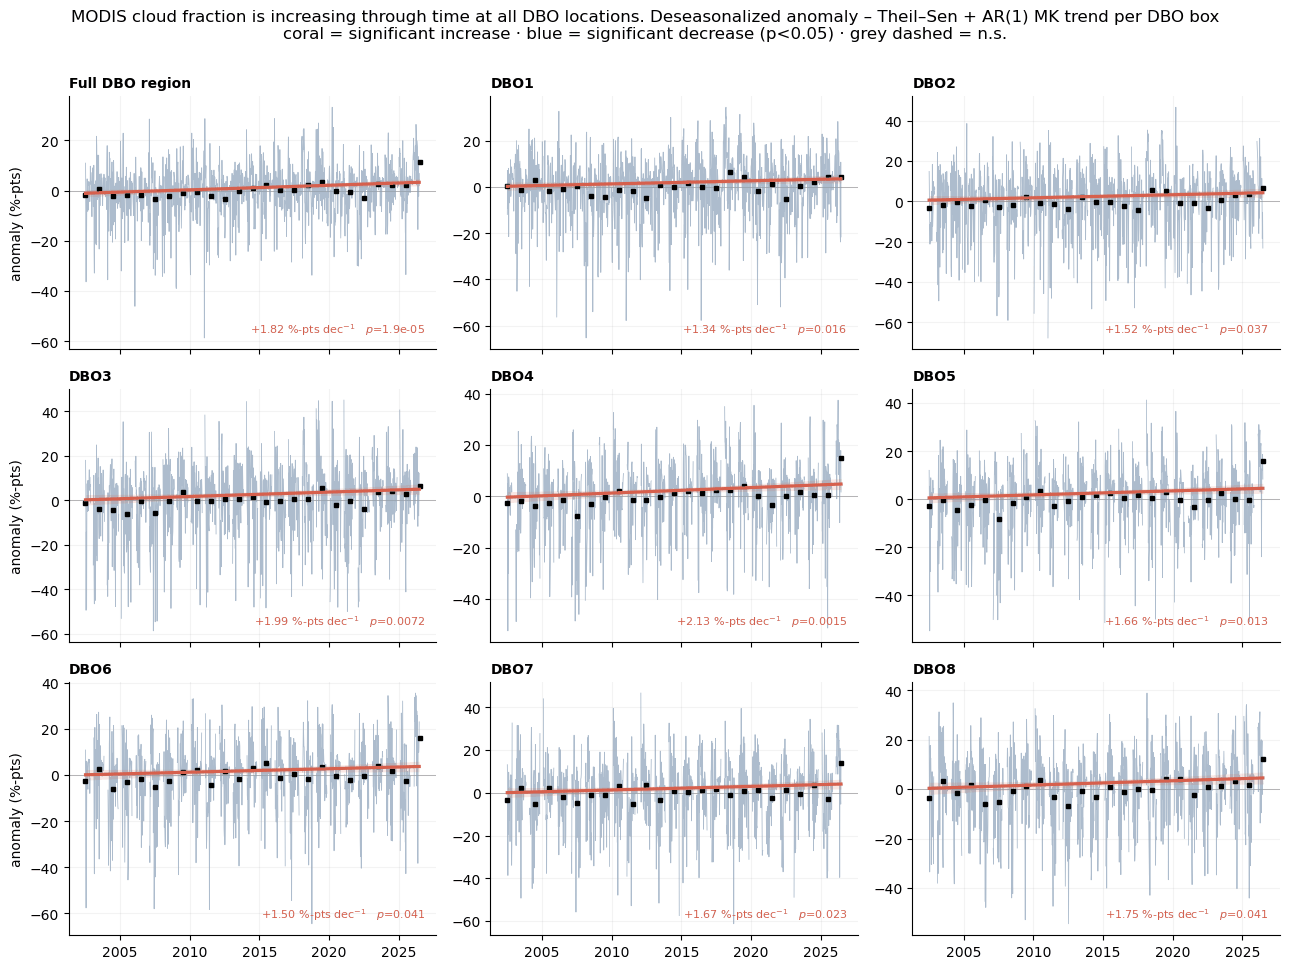

In [6]:
# ============================================================================
# Per-DBO-box deseasonalized-anomaly trend — Theil-Sen + AR(1) Mann-Kendall,
# styled like the OISSS SSS figure. Reusable: set CONFIG, then run.
# ============================================================================
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
from scipy.stats import theilslopes, kendalltau, norm, t as tdist

# ------------------------------- CONFIG -------------------------------------
BOX_SERIES = cf_box                # dict {name: xr.DataArray(time)} — chl_box / sst_box / cf_box / sss_box
UNIT       = "%-pts"               # anomaly-axis + slope unit (e.g. "PSU","°C","%-pts")
DESEASON   = "weekly"              # "weekly" (matches your existing graphs) | "daily" | "none" (already anomaly)
LOG10      = False                 # True for chl: work in log10, report %/decade
POS_LABEL, NEG_LABEL = "increase", "decrease"   # meaning of + / -  (e.g. "saltening","freshening")
POS_COLOR, NEG_COLOR = "#d6604d", "#2166ac"     # colors for significant + / - (coral / blue)
LINE_COLOR = "#8aa0b8"             # faint anomaly-series color
VAR_TITLE  = "MODIS cloud fraction"
ADD_FULL   = True                  # prepend a "Full DBO region" = mean across boxes
CLIM_HALFWIN = 8                   # +/- days for the daily DOY climatology
# ----------------------------------------------------------------------------

def _lag1(r):
    r = np.asarray(r, float); a, b = r[1:], r[:-1]; v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 10 else 0.0

def _anomaly(series):
    s = series
    if DESEASON == "weekly":
        s = s.resample(time="W").mean(skipna=True)
    y = np.asarray(s.values, float).copy()
    if LOG10:
        y[~np.isfinite(y) | (y <= 0)] = np.nan; y = np.log10(y)
    t   = pd.to_datetime(s["time"].values)
    dec = np.asarray(t.year + (t.dayofyear - 1) / 365.25, float)
    if DESEASON == "none":
        return dec, y
    if DESEASON == "weekly":
        key = (t.dayofyear.values // 7).astype(int); K = 54
    else:
        key = np.asarray(t.dayofyear, dtype=int); K = 367
    clim = np.full(K + 1, np.nan)
    for d in range(K + 1):
        if DESEASON == "weekly":
            m = (key == d) & np.isfinite(y)
        else:
            dd = np.abs(key - d); dd = np.minimum(dd, 366 - dd); m = (dd <= CLIM_HALFWIN) & np.isfinite(y)
        if m.sum() >= 5: clim[d] = np.nanmean(y[m])
    return dec, y - clim[key]

def _trend(x, y, minn=20):
    v = np.isfinite(x) & np.isfinite(y); x, y = np.asarray(x)[v], np.asarray(y)[v]; n = len(x)
    if n < minn: return None
    sl, ic, _, _ = theilslopes(y, x)
    tau, _ = kendalltau(x, y)
    a, b = np.polyfit(x, y, 1); phi = _lag1(y - (a * x + b))
    ne = n * (1 - phi) / (1 + phi) if (abs(phi) < 1 and phi != 0) else n; ne = float(max(min(ne, n), 3))
    p  = 2 * (1 - norm.cdf(abs(tau / np.sqrt(2*(2*ne+5)/(9*ne*(ne-1)))))) if ne > 4 else np.nan
    xbar = x.mean(); Sxx = np.sum((x - xbar) ** 2)
    s2adj = (np.sum((y - (sl*x+ic))**2) / max(n - 2, 1)) * (n / ne)
    per_dec = (10 ** (sl * 10) - 1) * 100 if LOG10 else sl * 10
    return dict(slope=sl, intercept=ic, p=p, per_dec=per_dec, n=n, dof=max(ne-2, 1),
                line_se=lambda xx: np.sqrt(s2adj * (1.0 / n + (xx - xbar) ** 2 / Sxx)),
                xmin=x.min(), xmax=x.max())

PANELS = dict(BOX_SERIES)
if ADD_FULL and "Full DBO region" not in PANELS:
    _t0 = next(iter(BOX_SERIES.values()))["time"].values
    _full = xr.DataArray(np.nanmean(np.stack([BOX_SERIES[n].values for n in BOX_SERIES]), axis=0),
                         dims="time", coords={"time": _t0})
    PANELS = {"Full DBO region": _full, **BOX_SERIES}

unit_lab = "%/dec" if LOG10 else f"{UNIT} dec$^{{-1}}$"
names = list(PANELS); ncol = 3; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True)
axes = np.atleast_1d(axes).ravel()

for ax, name in zip(axes, names):
    dec, anom = _anomaly(PANELS[name])
    ax.plot(dec, anom, "-", color=LINE_COLOR, lw=0.6, alpha=0.7, zorder=1)
    dfa = pd.DataFrame({"y": anom, "yr": np.floor(dec).astype(int)}).dropna()
    ga  = dfa.groupby("yr")["y"].mean()
    ax.plot(ga.index.values + 0.5, ga.values, "s", color="k", ms=3.2, zorder=3)
    ax.axhline(0, color="0.7", lw=0.7, zorder=0)

    r = _trend(dec, anom)
    if r is None:
        txt, col = "n<20", "0.55"
    else:
        sig = np.isfinite(r["p"]) and r["p"] < 0.05
        col = (POS_COLOR if r["slope"] > 0 else NEG_COLOR) if sig else "0.55"
        ls, lw = ("-", 2.3) if sig else ("--", 1.8)
        xs = np.linspace(r["xmin"], r["xmax"], 60); yp = r["intercept"] + r["slope"] * xs
        ax.plot(xs, yp, ls=ls, color=col, lw=lw, zorder=4)
        if sig:
            band = tdist.ppf(0.975, r["dof"]) * r["line_se"](xs)
            ax.fill_between(xs, yp - band, yp + band, color=col, alpha=0.15, lw=0, zorder=2)
        prec = 1 if LOG10 else 2
        txt = f"{r['per_dec']:+.{prec}f} {unit_lab}   $p$={r['p']:.2g}"
    ax.text(0.97, 0.05, txt, transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=col)
    ax.set_title(name, loc="left", fontweight="bold", fontsize=10)
    for spn in ("top", "right"): ax.spines[spn].set_visible(False)
    ax.grid(alpha=0.15)

for ax in axes[len(names):]: ax.axis("off")
for ax in axes[::ncol]: ax.set_ylabel(f"anomaly ({UNIT})")
fig.suptitle(f"{VAR_TITLE} is increasing through time at all DBO locations. Deseasonalized anomaly – Theil–Sen + AR(1) MK trend per DBO box\n"
             f"coral = significant {POS_LABEL} · blue = significant {NEG_LABEL} (p<0.05) · grey dashed = n.s.",
             fontsize=12, y=1.005)
plt.tight_layout(); plt.show()


## 19. Expected clear-sky days per pixel, year x month (Fig. S10, MODIS panel + table)

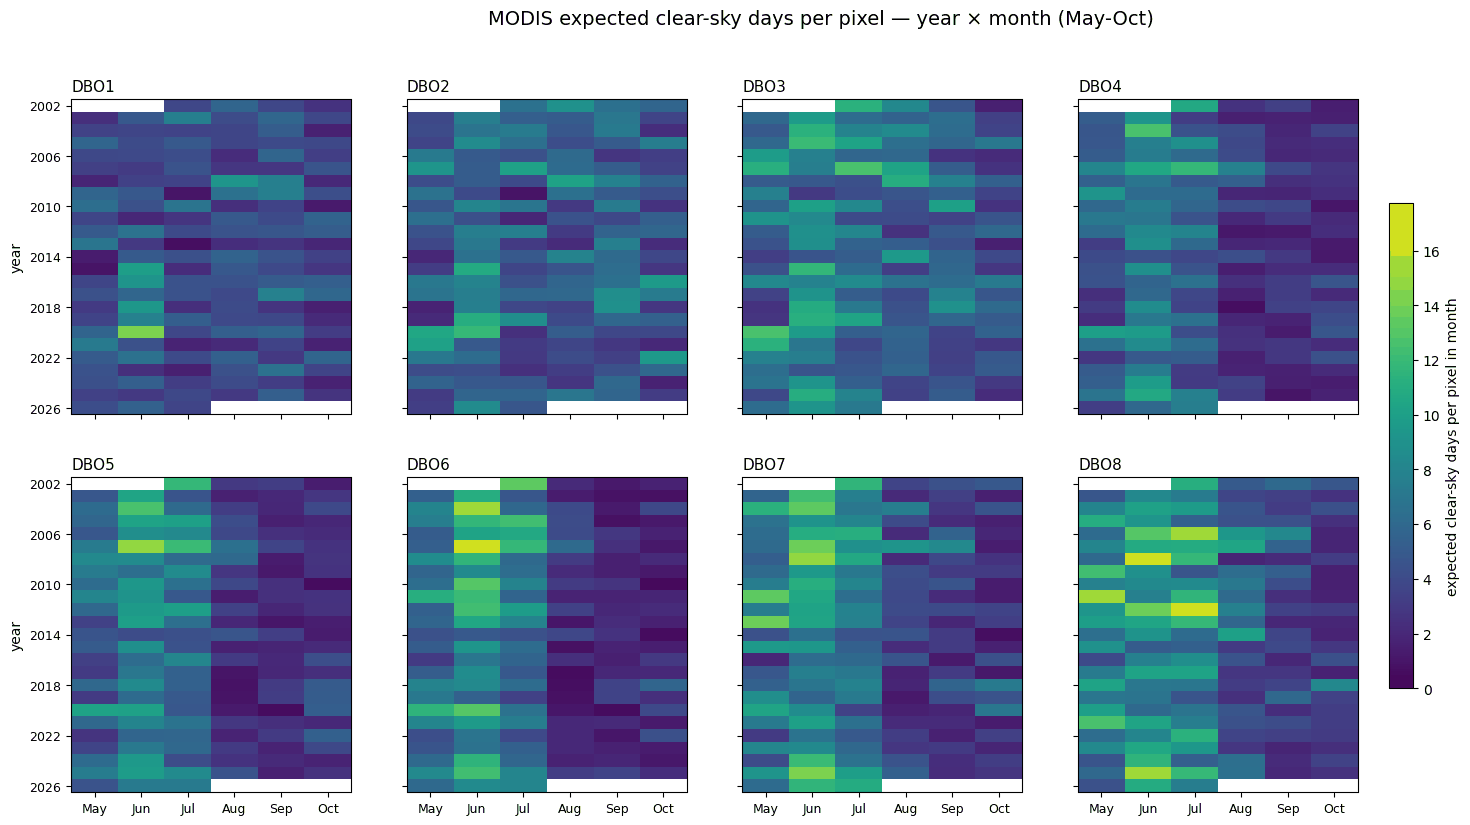

Mean expected clear-sky days per pixel, by calendar month:
         May   Jun  Jul  Aug  Sep  Oct
DBO box                               
DBO1     4.2   5.5  3.7  4.3  4.7  3.3
DBO2     5.2   7.0  4.9  5.1  5.8  4.6
DBO3     6.5   8.6  6.8  5.8  5.5  4.1
DBO4     5.2   7.9  5.9  2.8  2.4  2.5
DBO5     5.6   8.7  6.9  2.9  2.2  2.9
DBO6     6.5  10.3  7.2  2.4  2.0  2.1
DBO7     7.2  10.0  7.6  3.6  3.3  2.9
DBO8     8.1   9.8  9.1  5.3  3.7  3.0


In [18]:
# Expected clear-sky days per pixel, PER MONTH (May-Oct). Same 1 - CF logic,
# summed within each calendar month, scaled to the month's full length, and
# masked where a month has < MIN_OBS_M observed days.
import calendar
MONTHS    = [5, 6, 7, 8, 9, 10]
MIN_OBS_M = 20

monthly_clear = {}
for name in box_ts:
    s = box_ts[name]["daily_mean"].to_series().dropna()
    s = s[s.index.month.isin(MONTHS)]
    g = (1 - s).groupby([s.index.year, s.index.month])
    nobs, tot = g.count(), g.sum()
    ndays = pd.Series([calendar.monthrange(y, m)[1] for y, m in tot.index], index=tot.index)
    monthly_clear[name] = (tot * ndays / nobs).where(nobs >= MIN_OBS_M)

years = sorted({y for v in monthly_clear.values() for y, m in v.index})
vmax  = np.nanmax([v.max() for v in monthly_clear.values()])

fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
im = None
for ax, name in zip(axes.ravel(), monthly_clear):
    M = np.full((len(years), len(MONTHS)), np.nan)
    for (y, m), v in monthly_clear[name].items():
        M[years.index(y), MONTHS.index(m)] = v
    im = ax.imshow(M, aspect="auto", cmap="viridis", vmin=0, vmax=vmax,
                   interpolation="nearest")
    ax.set_title(name, fontsize=11, loc="left")
    ax.set_xticks(range(len(MONTHS)),
                  [calendar.month_abbr[m] for m in MONTHS], fontsize=9)
    ax.set_yticks(range(0, len(years), 4), years[::4], fontsize=9)
for ax in axes[:, 0]:
    ax.set_ylabel("year")
cb = fig.colorbar(im, ax=axes, shrink=0.7, pad=0.02)
cb.set_label("expected clear-sky days per pixel in month")
fig.suptitle("MODIS expected clear-sky days per pixel — year × month (May-Oct)",
             fontsize=14, y=0.98)
plt.show()

# Climatology: mean clear days per calendar month, per box
clim = pd.DataFrame({name: {calendar.month_abbr[m]: v.xs(m, level=1).mean() for m in MONTHS}
                     for name, v in monthly_clear.items()}).T
clim.index.name = "DBO box"
print("Mean expected clear-sky days per pixel, by calendar month:")
print(clim.round(1).to_string())
